# Lab 5: Put Uncertainty Into Your Project

---

## What this lab is

The last lab is about **your** project. You take the one number your project is built around and turn it into something a decision maker can trust: a range, a back-test, a scenario comparison and a figure for your paper. Everything you produce here can go straight into the Overleaf paper and the slides due on **6 December**.

* **Part A. Your key quantity.** Load it as a tidy table.
* **Part B. Back-test.** Hide the last years, project them with two models, count how often the truth falls inside the 90% band.
* **Part C. A range by simulation.** Pick the two most uncertain inputs of your pipeline, simulate, and find which matters most.
* **Part D. Scenarios.** At least two, compared with the interval width.
* **Part E. [OPTIONAL] One LLM-extracted variable**, evaluated as in Lab 5.
* **Part F. Communicate.** One fan chart and one paragraph for the paper.

## Conventions

* Same as before: **[QUAL]** 2-4 sentences, **[QUANT]** a number plus one sentence.
* If your project data are not ready, set `USE_DEMO = True`: the notebook runs on a demo series (synthetic steel-sector emissions) so you can build the code now and switch later. **Graded answers must use your project data.**
* Run **Kernel -> Restart & Run All** before submitting.

## Submission

Work in your **project group**. Push this notebook to your **project repository** in a folder `labs/`, and send the repo URL by email as before (1 email per group).

1. Full name: Camille Tanguy;     
Student ID: b00821659    

2. Full name: Charlotte Le Bihan;    
Student ID: b00818310     

3. Full name: Océane Tanios;     
Student ID: b00822694    

4. Full name: Inès Lebard;     
Student ID: b00820964

**Project role (consultant / data scientist / risk analyst):**      
Data scientist     

**Key quantity (one sentence, with unit):**      
Average CO2 emissions of new passenger cars registered in the EU-27 each year, weighted by registrations, in gCO2/km (WLTP)           

**Repo URL:**

## Setup (given)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
SEED = 42
rng = np.random.default_rng(SEED)

USE_DEMO = False   # set to False once your project data load below


def demo_series():
    # Synthetic sector emissions (MtCO2), 2005-2024: growth that slows down, plus noise.
    years = np.arange(2005, 2025)
    t = years - 2005
    trend = 900 + 70 * t - 1.9 * t**2
    noise = np.random.default_rng(7).normal(0, 35, len(t))
    return pd.DataFrame({"year": years, "value": trend + noise})

---
# PART A. Your key quantity

**Goal.** Create `series`: a DataFrame with columns `year` (int) and `value` (float), **one row per year**, sorted, for the single quantity your project is built around (e.g. sector emissions, a company's carbon cost, a portfolio's financed emissions, a capacity at risk). Also set `UNIT` (string) and `NAME` (string).

> **Hint.** If your project quantity is a panel (company x year), aggregate it for this lab (`groupby("year").value.sum()`). Keep at least **10 years** if you can.

In [2]:
DATA = Path("../../data")   # project data folder
EU27 = "AT BE BG HR CY CZ DK EE FI FR DE GR IE IT LV LT LU MT NL PL PT RO SK SI ES SE HU".split()

# EEA new cars, already aggregated by year x country x fuel type x fuel mode (see data/README.md)
eea = pd.read_csv(DATA / "eea/eea_summary.csv")
eea = eea[eea.country.isin(EU27)].copy()   # targets are EU only, drop NO, IS, GB
ft = eea.ft.fillna("").str.lower().str.strip()
eea["pt"] = np.select(
    [ft.isin(["electric", "hydrogen"]), ft.str.contains("electric"), eea.fm.eq("H")],
    ["BEV", "PHEV", "HEV"], "ICE")   # HEV only flagged from 2019, before it's inside ICE

if USE_DEMO:
    series, NAME, UNIT = demo_series(), "Demo sector emissions", "MtCO2"
else:
    yr = eea.groupby("year")[["n_wltp", "sum_wltp", "n_nedc", "sum_nedc", "sum_wltp_both", "sum_nedc_both"]].sum()
    # WLTP only exists properly from 2019. before that we scale NEDC up with the ratio
    # from cars that have both values (2019-2020)
    RATIO = yr.loc[[2019, 2020], "sum_wltp_both"].sum() / yr.loc[[2019, 2020], "sum_nedc_both"].sum()
    wltp = yr.sum_wltp / yr.n_wltp
    nedc = yr.sum_nedc / yr.n_nedc
    series = pd.DataFrame({"year": yr.index.astype(int),
                           "value": np.where(yr.index >= 2019, wltp, nedc * RATIO)})
    NAME, UNIT = "Avg CO2 of new cars, EU-27", "gCO2/km (WLTP)"
    print(f"WLTP/NEDC ratio = {RATIO:.3f}")
series


WLTP/NEDC ratio = 1.207


,year,value
0,2010,168.49
1,2011,163.07
2,2012,158.84
3,2013,152.55
4,2014,148.59
5,2015,143.82
6,2016,142.01
7,2017,142.50
8,2018,145.17
9,2019,147.17


### Q1 [QUAL] What is it, and where can it go wrong?

In 3-4 sentences: what does your quantity measure, which **decision** in your value proposal depends on it, and list its main sources of uncertainty labelled **A** (aleatoric), **E** (epistemic) or **S** (scenario), as in Lab 3 Q4.

**Your answer (Q1):**

It's the average CO2 per km of new cars sold in the EU-27 each year (weighted by registrations, WLTP test; 2010-2018 are NEDC values scaled up by the 1.21 ratio).

The decision it feeds is basically: is the market on track for 49.5 g/km in 2030 and 0 (or 11 if the relaxation passes) in 2035, and if not, is the fix more EVs or cleaner combustion cars.

Uncertainty:
- **S**: which EV path we get (IEA CPS vs STEPS, and if the 2035 proposal is adopted)
- **E**: the NEDC to WLTP conversion, the 2030 EV share that IEA doesn't actually give, PHEV official values being way lower than real use
- **A**: year to year noise in sales, like subsidies ending (Germany end of 2023) or the 2020 covid drop


---
# PART B. Back-test before you trust a band

Session 4 showed a 95% band whose real coverage fell to 6%. Here you test your own.

## B1. Two models, one hold-out

**Goal.** Write `fit_predict(train, horizon, model, level=0.90)` that fits on `train` (columns `year`, `value`) and returns a DataFrame for the next `horizon` years with `year`, `mean`, `lo`, `hi` (a **prediction interval**). Implement:

* `model="linear"`: OLS on `value ~ year`, Student-t prediction interval (formula from session 4, appendix A);
* `model="loglinear"`: OLS on `log(value) ~ year`, interval computed on the log scale then exponentiated (only if all values > 0).

Then hold out the **last 5 years**, fit both models on the rest, and create `backtest` with the predictions and the actual values.

> **Hint.** Centre the year (`t = year - year.mean()`) for numerical stability. Leverage: `x0' (X'X)^-1 x0`.

In [3]:
def fit_predict(train, horizon, model="linear", level=0.90):
    y = train.value.to_numpy(float)
    if model == "loglinear":
        if (y <= 0).any():
            raise ValueError("loglinear needs all values > 0")
        y = np.log(y)
    yrs = train.year.to_numpy(float)
    t_mean = yrs.mean()   # centre the year
    X = np.column_stack([np.ones_like(yrs), yrs - t_mean])
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    n, k = X.shape
    s2 = np.sum((y - X @ beta) ** 2) / (n - k)
    XtX_inv = np.linalg.inv(X.T @ X)

    fut = np.arange(yrs.max() + 1, yrs.max() + 1 + horizon)
    X0 = np.column_stack([np.ones_like(fut), fut - t_mean])
    lev = np.einsum("ij,jk,ik->i", X0, XtX_inv, X0)   # x0' (X'X)^-1 x0
    half = stats.t.ppf(0.5 + level / 2, n - k) * np.sqrt(s2 * (1 + lev))
    mean = X0 @ beta
    lo, hi = mean - half, mean + half
    if model == "loglinear":
        mean, lo, hi = np.exp(mean), np.exp(lo), np.exp(hi)
    return pd.DataFrame({"year": fut.astype(int), "mean": mean, "lo": lo, "hi": hi})


# hold out the last 5 years (2021-2025), fit on 2010-2020
H = 5
train, test = series.iloc[:-H], series.iloc[-H:]
backtest = pd.concat(
    [fit_predict(train, H, m).assign(model=m) for m in ["linear", "loglinear"]], ignore_index=True)
backtest = backtest.merge(test.rename(columns={"value": "actual"}), on="year")
backtest["inside"] = backtest.actual.between(backtest.lo, backtest.hi)
backtest


,year,mean,lo,hi,model,actual,inside
0,2021,131.94,121.06,142.82,linear,115.83,False
1,2022,129.04,117.72,140.36,linear,110.01,False
2,2023,126.13,114.32,137.95,linear,107.69,False
3,2024,123.23,110.88,135.57,linear,107.95,False
4,2025,120.32,107.41,133.24,linear,98.49,False
5,2021,132.70,123.36,142.76,loglinear,115.83,False
6,2022,130.16,120.64,140.44,loglinear,110.01,False
7,2023,127.67,117.94,138.21,loglinear,107.69,False
8,2024,125.23,115.27,136.05,loglinear,107.95,False
9,2025,122.83,112.63,133.96,loglinear,98.49,False


### Q2 [QUANT + QUAL] Did your band hold?

(a) For each model, how many of the 5 held-out years fall inside the 90% band? (b) With 5 years, how many misses would make you doubt a 90% band? Use the binomial from session 6, station 3 (compute P(X >= k) for X ~ Bin(5, 0.1)). (c) Which model do you keep, and what does the gap between them tell you?

held-out years inside the 90% band:
model
linear       0
loglinear    0 

P(misses >= 0) = 1.00000
P(misses >= 1) = 0.40951
P(misses >= 2) = 0.08146
P(misses >= 3) = 0.00856
P(misses >= 4) = 0.00046
P(misses >= 5) = 0.00001


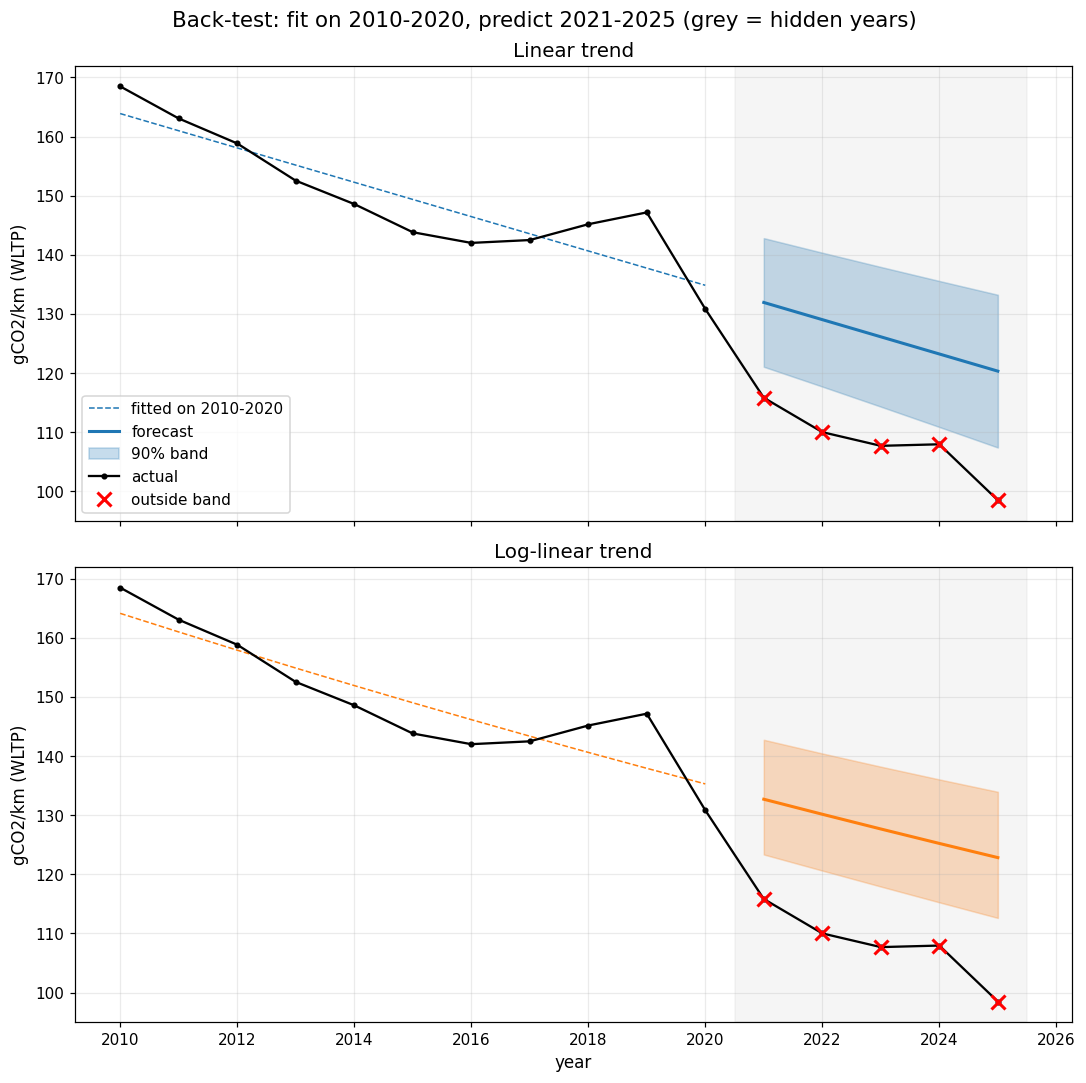

In [4]:
hits = backtest.groupby("model").inside.sum()
print("held-out years inside the 90% band:")
print(hits.to_string(), "\n")

# if the band really is 90%, misses ~ Bin(5, 0.1)
for k in range(6):
    print(f"P(misses >= {k}) = {stats.binom.sf(k - 1, 5, 0.1):.5f}")

# one panel per model so the bands don't overlap
fig, axes = plt.subplots(2, 1, figsize=(10, 10), sharex=True, sharey=True)
for ax, m, c, name in zip(axes, ["linear", "loglinear"], ["C0", "C1"], ["Linear trend", "Log-linear trend"]):
    b = backtest[backtest.model == m]
    # fitted line on the training years (same OLS as fit_predict)
    if m == "linear":
        fit = np.polyval(np.polyfit(train.year, train.value, 1), train.year)
    else:
        fit = np.exp(np.polyval(np.polyfit(train.year, np.log(train.value), 1), train.year))
    ax.plot(train.year, fit, color=c, ls="--", lw=1, label="fitted on 2010-2020")
    ax.plot(b.year, b["mean"], color=c, lw=2, label="forecast")
    ax.fill_between(b.year, b.lo, b.hi, color=c, alpha=0.25, label="90% band")
    ax.plot(series.year, series.value, "k.-", label="actual")
    ax.plot(b.year[~b.inside], b.actual[~b.inside], "rx", ms=9, mew=2, label="outside band")
    ax.axvspan(2020.5, 2025.5, color="grey", alpha=0.08)
    ax.set_title(name, fontsize=13)
    ax.set_ylabel(UNIT, fontsize=11)
axes[1].set_xlabel("year", fontsize=11)
axes[0].legend(fontsize=10)
fig.suptitle("Back-test: fit on 2010-2020, predict 2021-2025 (grey = hidden years)", fontsize=14)
plt.tight_layout();


**Your answer (Q2):**

(a) Zero for both. Linear 0/5, loglinear 0/5. Every held-out year is under the band, the real value is 16 to 22 g/km lower than the forecast.

(b) If the band was really 90%, misses ~ Bin(5, 0.1): P(X >= 2) = 0.08 and P(X >= 3) = 0.009. So 2 misses already looks suspicious and 3 is basically a no. We have 5, P = 0.00001, so the band is not a 90% band at all.

(c) Neither really works. If we have to pick it's the linear one (a bit closer), but the two are only 1-2 g/km apart while they both miss by about 20, so the choice between them doesn't matter much. The problem is the break in 2020-21 when EVs took off with the 95 g/km target, a trend on 2010-2020 just can't see that coming. The rolling back-test (B2) says the same, coverage is 40-67% instead of 90%. So we won't use a trend for the projection, we go through the EV share + combustion car CO2 in Part C.


## B2. [OPTIONAL] Rolling back-test

Repeat B1 with a **rolling origin**: for every cutoff year from the 10th year onwards, fit on the past and predict 1 to 3 years ahead. Report the coverage by horizon (1, 2, 3 years) for each model. This gives many more test points than a single hold-out.

In [5]:
# cutoffs from the 10th year (2019) on, predict 1-3 years ahead when we have the actual
rows = []
for cut in series.year.iloc[9:-1]:
    tr = series[series.year <= cut]
    for m in ["linear", "loglinear"]:
        f = fit_predict(tr, 3, m).merge(series.rename(columns={"value": "actual"}), on="year")
        f["h"] = f.year - cut
        rows.append(f.assign(model=m, cutoff=cut))
roll = pd.concat(rows, ignore_index=True)
roll["inside"] = roll.actual.between(roll.lo, roll.hi)
roll.groupby(["model", "h"]).inside.agg(["sum", "count", "mean"]).rename(columns={"sum": "inside", "count": "n", "mean": "coverage"})


inside  n  coverage
model     h                     
linear    1       4  6      0.67
          2       3  5      0.60
          3       2  4      0.50
loglinear 1       4  6      0.67
          2       2  5      0.40
          3       2  4      0.50

---
# PART C. A range by simulation

Your key quantity is computed from inputs (e.g. capacity x utilisation x emission factor, or emissions x carbon price x pass-through). Pick the **two inputs you are least sure about**.

**Goal.** Fill in `compute_quantity(input1, input2)` with your project formula (vectorised with NumPy), choose a distribution for each input with a **written justification**, and run `n = 5,000` draws for your target year. Report the median and 90% interval. Then run a **one-at-a-time sensitivity**: fix each input at its median in turn and report the relative half-width.

> **Demo.** 2030 emissions = production (Mt) x emission factor (tCO2/t). Production ~ Normal(800, 40); factor ~ Triangular(1.5, 1.85, 2.3).

In [6]:
N = 5_000
TARGET = 2030

# 2025 starting point by group. combustion = petrol/diesel/LPG/... + normal hybrids
eea["grp"] = eea.pt.replace({"HEV": "COMB", "ICE": "COMB"})
g = eea.groupby(["year", "grp"])[["regs", "n_wltp", "sum_wltp"]].sum()
regs = g.regs.unstack()
co2 = (g.sum_wltp / g.n_wltp).unstack()
share = regs.div(regs.sum(axis=1), axis=0)
F25 = regs.loc[2025, "PHEV"] / regs.loc[2025, ["BEV", "PHEV"]].sum()   # PHEV part of EV sales in 2025
C_PHEV = co2.loc[2025, "PHEV"]                                       # kept fixed

# PHEVs almost disappear by 2035 in IEA (PHEV part of EV sales, Europe 2035), so the PHEV part
# goes down in a straight line from 2025 to that. no IEA path for a slow scenario -> stays at 2025
iea = pd.read_csv(DATA / "iea/iea_ev_cars.csv")
p35 = iea[(iea.parameter == "EV sales") & iea.category.str.startswith("Projection")].pivot_table(
    index="category", columns="powertrain", values="value")
F35 = (p35.PHEV / p35.EV).rename({"Projection-STEPS": "IEA STEPS", "Projection-CPS": "IEA CPS"})


def f_phev(year, scen):
    if scen not in F35:
        return F25
    return F25 + (F35[scen] - F25) * (np.asarray(year) - 2025) / 10


F30 = f_phev(TARGET, "IEA STEPS")
print(f"2025: EV share {share.loc[2025, ['BEV', 'PHEV']].sum():.1%}, PHEV part of EVs {F25:.0%}, "
      f"PHEV {C_PHEV:.1f} g/km, combustion {co2.loc[2025, 'COMB']:.1f} g/km")
print(f"PHEV part of EVs in 2035 (IEA): STEPS {F35['IEA STEPS']:.1%}, CPS {F35['IEA CPS']:.1%} -> STEPS 2030: {F30:.0%}")


def compute_quantity(ev_share, c_comb, f=F30):
    # avg new car CO2 = EVs (BEV at 0, PHEV at C_PHEV, f = PHEV part of EVs) + combustion cars
    return ev_share * f * C_PHEV + (1 - ev_share) * c_comb


# input 1: EV share 2030. IEA STEPS = about 7M EVs sold in the EU in 2030, the share depends on
# how big the market is, it went from 9.3M to 13.0M over 2019-2025
rep = pd.read_csv(DATA / "iea/iea_report_figures.csv")
EV_2030 = rep.query("scenario == 'STEPS' and year == 2030").value.item()   # million cars
mkt = regs.loc[2019:].sum(axis=1) / 1e6
ev_lo, ev_mode, ev_hi = EV_2030 / mkt.max(), EV_2030 / mkt.loc[2025], EV_2030 / mkt.min()
ev_share = rng.triangular(ev_lo, ev_mode, ev_hi, N)

# input 2: combustion car CO2 in 2030 = trend on 2021-2025 (the WLTP years) + its prediction interval
comb = pd.DataFrame({"year": range(2021, 2026), "value": co2.loc[2021:2025, "COMB"].values})
fc = fit_predict(comb, TARGET - 2025, "linear").iloc[-1]
se = (fc.hi - fc["mean"]) / stats.t.ppf(0.95, len(comb) - 2)
c_comb = fc["mean"] + se * rng.standard_t(len(comb) - 2, N)
print(f"EV share 2030 ~ Tri({ev_lo:.2f}, {ev_mode:.2f}, {ev_hi:.2f}), "
      f"combustion CO2 2030 ~ {fc['mean']:.1f} + {se:.2f} * t(3)")


def summary(x):
    q5, q50, q95 = np.percentile(x, [5, 50, 95])
    return pd.Series({"median": q50, "lo90": q5, "hi90": q95, "rel_half_width": (q95 - q5) / 2 / q50})


draws = compute_quantity(ev_share, c_comb)
sens = pd.DataFrame({
    "both uncertain": summary(draws),
    "EV share fixed": summary(compute_quantity(np.median(ev_share), c_comb)),
    "combustion CO2 fixed": summary(compute_quantity(ev_share, np.median(c_comb))),
}).T
sens


2025: EV share 27.5%, PHEV part of EVs 36%, PHEV 32.0 g/km, combustion 131.6 g/km
PHEV part of EVs in 2035 (IEA): STEPS 4.2%, CPS 0.7% -> STEPS 2030: 20%
EV share 2030 ~ Tri(0.54, 0.66, 0.75), combustion CO2 2030 ~ 125.5 + 1.87 * t(3)


,median,lo90,hi90,rel_half_width
both uncertain,48.03,39.55,57.38,0.19
EV share fixed,48.06,46.50,49.57,0.03
combustion CO2 fixed,48.06,39.66,57.24,0.18


**Why these distributions**

- **EV share 2030 ~ Triangular(0.54, 0.66, 0.75).** IEA STEPS gives about 7M EVs sold in the EU in 2030 (GEVO 2026 p. 233) but not the share. So we divide by the market size: the 2025 market (10.6M) for the mode, and the biggest / smallest market of 2019-2025 (13.0M / 9.3M) for the ends. Triangular because we have a min, a most likely and a max and not much more than that. Quick check: an S-curve from 27.5% in 2025 to about 92% in 2035 (IEA) gives 68% in 2030, so inside the range.

- **Combustion car CO2 2030 ~ 125.5 + 1.87 t(3).** Linear trend of 2021-2025 (-1.35 g/km per year) with its own prediction interval, t with 3 df because we only have 5 points. Combustion cars get better slowly and smoothly (more hybrids), no big break like with EVs, so a trend is less crazy here than for the total. Still, 5 points is not a lot.

- PHEV CO2 kept at its 2025 value (32 g/km). The PHEV part of EV sales goes down in a straight line from 36% (2025) to the IEA 2035 level (4.2% in STEPS, 0.7% in CPS, Europe data), so it's 20% in 2030 for STEPS. Keeping 36% forever would make CO2 too high, mostly in 2035. For the slow scenario there is no IEA path so it stays at 36%.


### Q3 [QUANT + QUAL] Which input drives the range?

(a) Median and 90% interval for your target year. (b) Which input, once fixed, shrinks the interval most? Is it **aleatoric** or **epistemic**? (c) If you had one more week, what data would you collect to shrink it, and which part of the range would remain whatever you do?

**Your answer (Q3):**

(a) 2030: median 48.0 g/km, 90% interval 39.6 to 57.4 g/km. The target is 49.5, so it's inside the range, a bit more likely met than not (60% of draws).

(b) The EV share. Fixed at its median, the half-width goes from 19% to 3%. Fixing combustion car CO2 does almost nothing (18%). It's mostly **epistemic**: we don't really know IEA's 2030 share for the EU, we rebuilt it from 7M cars / market size. A bit aleatoric too, since the market size moves every year (covid, subsidies).

(c) We'd try to get IEA's actual 2030 EU number (the data behind their figure, or just ask them), and look at the 2026 monthly registrations (ACEA) to see if the EV share is really speeding up. What stays whatever we do is the year to year noise in sales and what people end up buying. Which policy ends up in place also stays, but that's the scenario part (D), not this range.


---
# PART D. Scenarios

**Goal.** Define at least **two scenarios** relevant to your role (e.g. an NGFS-style orderly vs delayed transition, a carbon price of 50 vs 150 USD/t, 30% of blast furnaces retired). Implement each as a change to the inputs of Part C, rerun the simulation, and create a table `scen` with the median and 90% interval per scenario.

EV share 2030: slow 35%, STEPS 66%, CPS 86%
                     median  lo90   hi90  rel_half_width  width90  gap_to_target  P(meet target)
Slow (2021-25 pace)   85.65 69.74 100.81            0.18    31.07          36.15            0.01
IEA STEPS             48.03 39.55  57.38            0.19    17.83          -1.47            0.60
IEA CPS               23.42 12.57  35.70            0.49    23.13         -26.08            1.00


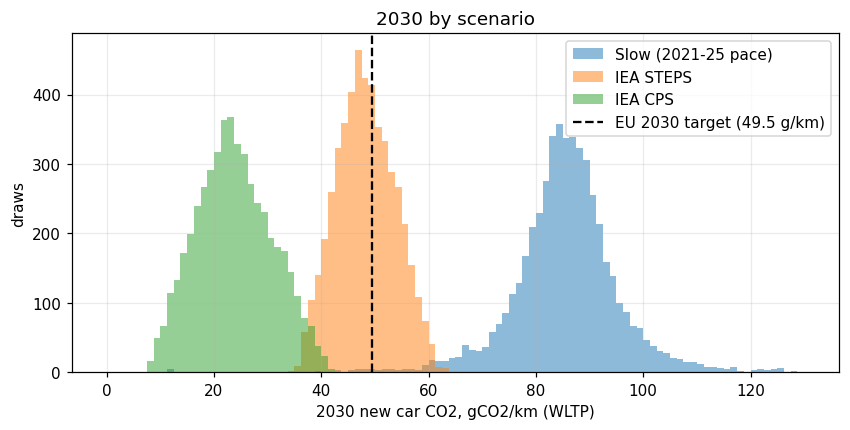

In [7]:
targets = pd.read_csv(DATA / "eu/eu_targets.csv")
TARGET_GKM = targets[(targets.status == "in force") & (targets.period_start <= TARGET)
                     & (targets.period_end >= TARGET)].target_gkm.item()   # 49.5 for 2030

# scenarios move the EV share (and the PHEV part with it), combustion car CO2 stays as in Part C

# 1) slow: EV share keeps its 2021-2025 pace (linear trend + prediction interval)
evs = pd.DataFrame({"year": range(2021, 2026), "value": share.loc[2021:2025, ["BEV", "PHEV"]].sum(axis=1).values})
f = fit_predict(evs, TARGET - 2025, "linear").iloc[-1]
se_ev = (f.hi - f["mean"]) / stats.t.ppf(0.95, len(evs) - 2)
ev_slow = np.clip(f["mean"] + se_ev * rng.standard_t(len(evs) - 2, N), 0, 1)

# 2) IEA STEPS (with the 2035 relaxation) = Part C

# 3) IEA CPS (current law, 0 g/km in 2035): IEA has the EU at nearly 100% EV in 2035 but no 2030 number,
#    so S-curve (straight line in logit) from 2025 to 99% in 2035, 2030 is halfway.
#    same market size trick as STEPS for the spread
logit = lambda p: np.log(p / (1 - p))
s25 = share.loc[2025, ["BEV", "PHEV"]].sum()
cps_mode = 1 / (1 + np.exp(-(logit(s25) + logit(0.99)) / 2))
vol = cps_mode * mkt.loc[2025]
ev_cps = rng.triangular(vol / mkt.max(), cps_mode, min(vol / mkt.min(), 1), N)
print(f"EV share 2030: slow {f['mean']:.0%}, STEPS {ev_mode:.0%}, CPS {cps_mode:.0%}")

scen_draws = {"Slow (2021-25 pace)": compute_quantity(ev_slow, c_comb, F25),
              "IEA STEPS": draws,
              "IEA CPS": compute_quantity(ev_cps, c_comb, f_phev(TARGET, "IEA CPS"))}
scen = pd.DataFrame({k: summary(v) for k, v in scen_draws.items()}).T
scen["width90"] = scen.hi90 - scen.lo90
scen["gap_to_target"] = scen["median"] - TARGET_GKM
scen["P(meet target)"] = [np.mean(v <= TARGET_GKM) for v in scen_draws.values()]
print(scen.round(2).to_string())

fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(0, 130, 105)   # same bins for all, otherwise heights are not comparable
for k, v in scen_draws.items():
    ax.hist(v, bins=bins, alpha=0.5, label=k)
ax.axvline(TARGET_GKM, color="k", ls="--", label=f"EU 2030 target ({TARGET_GKM} g/km)")
ax.set(xlabel=f"{TARGET} new car CO2, {UNIT}", ylabel="draws", title=f"{TARGET} by scenario")
ax.legend();


### Q4 [QUANT + QUAL] Scenario gap vs interval width

Compare the largest **gap between scenario medians** with the **width** of the interval within one scenario. Which is bigger? What does that mean for how you present your result (one fan chart, or one band per scenario)?

**Your answer (Q4):**

Largest gap between medians: slow pace (85.7 g/km) vs IEA CPS (23.4 g/km) = **62 g/km**. Width of the 90% interval inside one scenario is 18 g/km for STEPS and at most 31 g/km (slow). So the scenario gap is 2 to 3.5 times bigger than the range inside any scenario.

Even STEPS vs CPS alone is 25 g/km apart, already more than the STEPS width.

So it would be wrong to merge everything into one fan chart, you'd get a huge band and lose the point, which is that the result depends mostly on which EV path we're on. We show one band per scenario, with the target line. Also only STEPS is "on the edge" (60% chance to meet 49.5), slow basically never meets it and CPS always does.


---
# PART E. [OPTIONAL] One LLM-extracted variable

If your project uses a variable you could only get from text (targets, ownership shares, plant start dates...):

1. Extract it with an LLM for your companies, using the schema and parser pattern of Lab 5.
2. Label **at least 10** cases by hand (your gold sample).
3. Report accuracy with a **Beta(1,1) 90% interval** and the list of errors by type.

### Q5 [QUANT + QUAL] (optional)

Accuracy with interval, main error type, and one sentence on how the errors could bias your key quantity.

In [8]:
# skipped (optional): our project has no variable that comes from text, everything is from EEA / IEA tables


---
# PART F. Communicate

## F1. The figure for your paper

**Goal.** One fan chart: history as a line, then for your target years the median and the **50% and 90%** bands, one colour per scenario (at least the baseline). Label the axes with units, state the scenario in the legend, and save it as `fig_uncertainty.png` for Overleaf.

> **Hint.** Use the Part C/D draws for the target year and widen the bands from today's value to that year, or simulate the path year by year. Do not use a trend that failed the back-test in Part B. `plt.fill_between(...)`.

p5   p50    p95
Slow (2021-25 pace) 2030 69.70 85.70 100.80
                    2035 43.00 72.80 101.40
IEA STEPS           2030 39.50 48.00  57.40
                    2035  7.70 13.10  22.00
IEA CPS             2030 12.60 23.40  35.70
                    2035  0.40  1.50   5.00

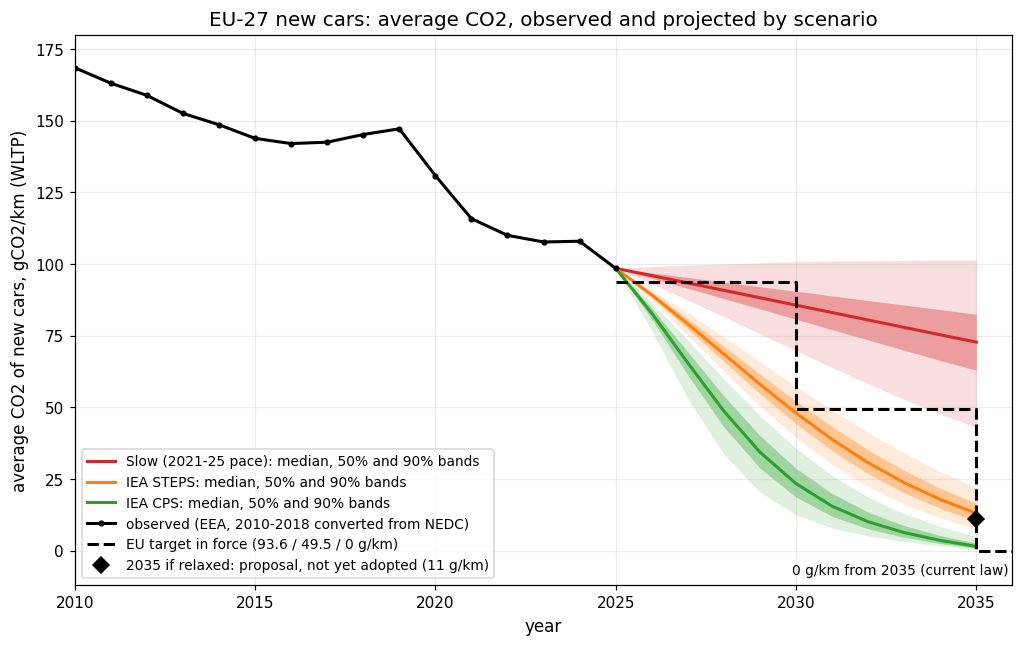

In [9]:
YEARS = np.arange(2025, 2036)
c25 = co2.loc[2025, "COMB"]


def paths(ev2030, c2030, scen):
    # year by year 2025-2035 for each draw:
    # EV share on an S-curve (straight line in logit) through 2025 and its 2030 draw, kept going to 2035
    # combustion CO2 on a straight line through 2025 and its 2030 draw, PHEV part as in f_phev
    k = (YEARS - 2025) / (TARGET - 2025)
    ev2030 = np.clip(ev2030, 1e-3, 1 - 1e-3)
    ev = 1 / (1 + np.exp(-(logit(s25) + np.outer(logit(ev2030) - logit(s25), k))))
    cc = c25 + np.outer(c2030 - c25, k)
    return compute_quantity(ev, cc, f_phev(YEARS, scen))   # draws x years


scen_ev = {"Slow (2021-25 pace)": ev_slow, "IEA STEPS": ev_share, "IEA CPS": ev_cps}
colors = {"Slow (2021-25 pace)": "C3", "IEA STEPS": "C1", "IEA CPS": "C2"}

fig, ax = plt.subplots(figsize=(11, 6.5))
fan = {}
for name, ev2030 in scen_ev.items():
    q = np.percentile(paths(ev2030, c_comb, name), [5, 25, 50, 75, 95], axis=0)
    fan[name] = pd.DataFrame(q.T, index=YEARS, columns=["p5", "p25", "p50", "p75", "p95"])
    c = colors[name]
    ax.fill_between(YEARS, q[0], q[4], color=c, alpha=0.15, lw=0)
    ax.fill_between(YEARS, q[1], q[3], color=c, alpha=0.35, lw=0)
    ax.plot(YEARS, q[2], color=c, lw=2, label=f"{name}: median, 50% and 90% bands")

ax.plot(series.year, series.value, "k.-", lw=2, label="observed (EEA, 2010-2018 converted from NEDC)")

# EU fleet targets in force (93.6 / 49.5 / 0) + the 2035 proposal
tgt = targets[targets.status == "in force"]
tyears = np.arange(2025, 2037)   # 2036 just so the 2035 step shows
tvals = [tgt[(tgt.period_start <= y) & (tgt.period_end >= y)].target_gkm.item() for y in tyears]
ax.step(tyears, tvals, where="post", color="k", ls="--", lw=2, label="EU target in force (93.6 / 49.5 / 0 g/km)")
prop = targets[targets.status.str.startswith("proposal")].target_gkm.item()
ax.plot(2035, prop, "kD", ms=7, label=f"2035 if relaxed: proposal, not yet adopted ({prop:g} g/km)")
ax.text(2035.9, -7, "0 g/km from 2035 (current law)", ha="right", va="center", fontsize=9)

ax.set_xlim(2010, 2036)
ax.set_ylim(-12, 180)
ax.set_xlabel("year", fontsize=11)
ax.set_ylabel(f"average CO2 of new cars, {UNIT}", fontsize=11)
ax.set_title("EU-27 new cars: average CO2, observed and projected by scenario", fontsize=13)
ax.legend(fontsize=9, loc="lower left")
fig.savefig("fig_uncertainty.png", dpi=200, bbox_inches="tight")

pd.concat({k: v.loc[[2030, 2035], ["p5", "p50", "p95"]] for k, v in fan.items()}).round(1)


## F2. The paragraph for your paper

### Q6 [QUAL] About 120 words

Write the **uncertainty and limitations** paragraph of your Overleaf paper. Include: the scenario and horizon, the median and 90% interval, the back-test result (how many held-out years fell inside), the input that drives the range, the largest **scenario** gap, and one limitation of your method. Use one calibrated word from the IPCC scale.

### Q7 [QUAL] One sentence for your slides

Finish this sentence for your role's value proposal: *"Because the range is this wide, the decision that changes is ..."*

**Your answer (Q6):**

In the IEA Stated Policies scenario, new EU-27 cars average 48 g/km in 2030 (90% interval 40 to 57), so meeting the 49.5 g/km target is *about as likely as not* (60% of draws). We don't use a trend for this: fitted on 2010-2020, a linear trend got 0 of the 5 years 2021-2025 inside its 90% band, because of the EV take-off after 2020. The range comes almost all from the 2030 EV share (fixing it cuts the half-width from 19% to 3%). The scenario matters more: slow EV growth (86 g/km) vs IEA Current Policies (23 g/km) is a 62 g/km gap. Limitation: the EU 2030 EV share is rebuilt from IEA's 7M cars, and PHEVs use official test values, way below real use.


**Your answer (Q7):**

Because the range is this wide, the decision that changes is what to watch and push: hitting 2030 depends on how fast EV sales grow in the next few years, not on cleaner combustion cars, if the EV share stays at the 2021-25 pace the target is missed by around 35 g/km whatever else happens.
